# 2 - SIR on a network

We keep the S → I → R states we already know. Now each person has a state, and susceptible people can only be infected by their infected neighbours. We will count individual people, so results are stochastic.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

### 1 - Store one state per person 

A **dictionary** stores pairs of keys and values. Here the key is a person's number and the value is a string: `"S"`, `"I"` or `"R"`. `state[2]` reads person 2's state; `state[2] = "I"` changes it.

Start with a chain: 0—1—2—3—4—5. Person 0 is infected.

{0: 'I', 1: 'S', 2: 'S', 3: 'S', 4: 'S', 5: 'S'}
Person 1: S


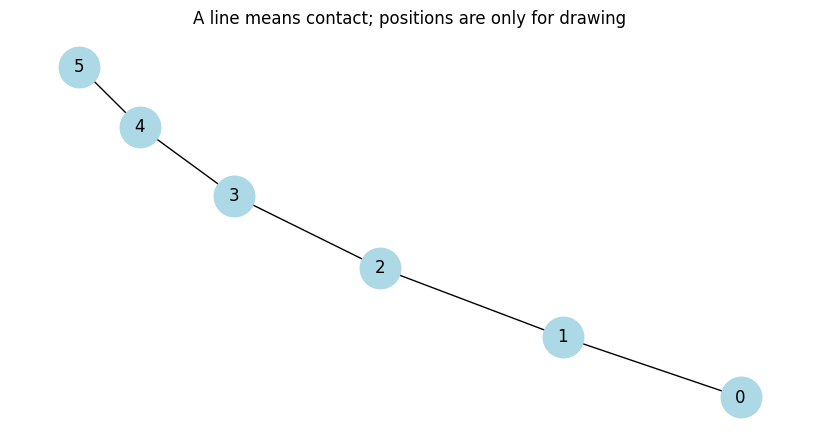

In [2]:
### Method 1
#people = [0, 1, 2, 3, 4, 5]
#contacts = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]
#G = nx.Graph()              
#G.add_nodes_from(people)      
#G.add_edges_from(contacts)

### Method 2
G = nx.path_graph(6) 

###assign state to each person
state = {}
for person in G.nodes():
    state[person] = "S"
state[0] = "I"
print(state)
print("Person 1:", state[1])

### Plot
plt.figure(figsize=(8, 4))
nx.draw(G, with_labels=True, node_color="lightblue", node_size=850)
plt.title("A line means contact; positions are only for drawing")
plt.show()

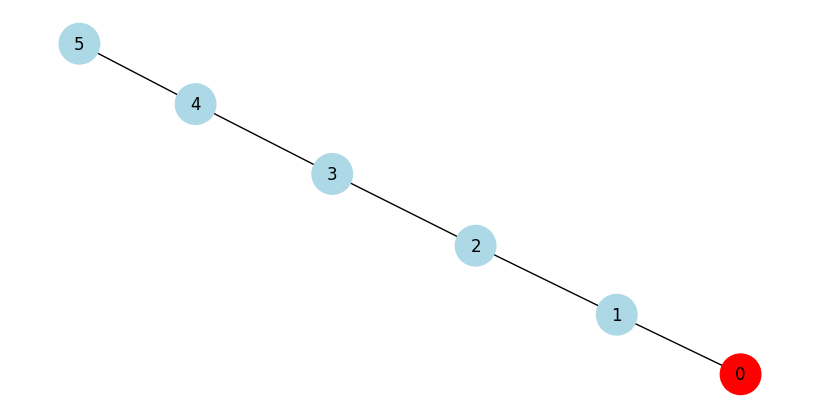

In [3]:
colors = {"S": "lightblue", "I": "red", "R": "green"}
node_colors = [colors[state[n]] for n in G.nodes()]

plt.figure(figsize=(8, 4))
nx.draw(G, with_labels=True, node_color=node_colors, node_size=850)
plt.show()

**Your turn:** starting from this state, which person can become infected during the first day? Can person 2 become infected that same day? Write your prediction before continuing.

### 1b - Finding the Neighbors 

In [4]:
for person in G.nodes():
    print(f"Person {person}: {state[person]}")
    print(f'Neighbors of person {person}: {list(G.neighbors(person))}')

Person 0: I
Neighbors of person 0: [1]
Person 1: S
Neighbors of person 1: [0, 2]
Person 2: S
Neighbors of person 2: [1, 3]
Person 3: S
Neighbors of person 3: [2, 4]
Person 4: S
Neighbors of person 4: [3, 5]
Person 5: S
Neighbors of person 5: [4]


### 2 - Simulating one day: SIR transition rules

We now define a function `one_day()` that simulates **one day of epidemic spreading** on our network.

Each person can be in one of three states:
- **S (Susceptible):** Can become infected through contact with an infected neighbour. Each infected neighbour has an independent probability `p_transmit` of transmitting the infection.
- **I (Infected):** Can infect susceptible neighbours and has a probability `p_recover` of recovering each day.
- **R (Recovered):** Remains recovered and cannot be infected again.

**How does the function work?**

1. We create `next_state = state.copy()` to store the states for the next day.
2. We loop through all people in the network.
3. For each susceptible person, we check their infected neighbours and simulate possible transmission using `random.random()`.
4. For each infected person, we randomly determine whether they recover.
5. Finally, we return `next_state`, containing the updated states of all individuals.

**Why do we use two dictionaries?**

`state` represents **today**, while `next_state` represents **tomorrow**.

All transitions are computed using today's states. This ensures that a person infected during the current day can only start spreading the infection on the following day.

This is called a **synchronous update** and prevents the simulation results from depending on the order in which we visit the nodes.

In [5]:
state

{0: 'I', 1: 'S', 2: 'S', 3: 'S', 4: 'S', 5: 'S'}

In [6]:
import random

def one_day(G, state, p_transmit, p_recover):

    next_state = state.copy()

    for person in G.nodes():

        if state[person] == "S":

            for neighbor in G.neighbors(person):
                if state[neighbor] == "I" and random.random() < p_transmit:
                    next_state[person] = "I"
                    break

        elif state[person] == "I":

            if random.random() < p_recover:
                next_state[person] = "R"

    return next_state

### 3 - Trace the code by hand 

For a simple check, use certain transmission (`1.0`) and no recovery (`0.0`). Predict the states after day 1 and day 2, then run:

In [7]:
rng = np.random.default_rng(7)
day1 = one_day(G, state, 1.0, 0.0)
day2 = one_day(G, day1, 1.0, 0.0)
print("Day 0:", state)
print("Day 1:", day1)
print("Day 2:", day2)

Day 0: {0: 'I', 1: 'S', 2: 'S', 3: 'S', 4: 'S', 5: 'S'}
Day 1: {0: 'I', 1: 'I', 2: 'S', 3: 'S', 4: 'S', 5: 'S'}
Day 2: {0: 'I', 1: 'I', 2: 'I', 3: 'S', 4: 'S', 5: 'S'}



### 4 - Repeat the same day rule 

The wrapper below initializes the states, counts S/I/R, and calls `one_day` repeatedly. `list(state.values())` collects the states; `.count("I")` counts infected people. `history` keeps a snapshot so we can draw the same people on different days.

Day 0 is recorded before any updates. `days + 1` therefore includes the initial condition.

In [23]:
def simulate(G, first_infected=0, p_transmit=0.25, p_recover=0.2,
             days=40):
    state = {}
    for person in G.nodes():
        state[person] = "S"
    state[first_infected] = "I"

    S, I, R = [], [], []
    history = []
    for day in range(days + 1):
        values = list(state.values())
        S.append(values.count("S"))
        I.append(values.count("I"))
        R.append(values.count("R"))
        history.append(state.copy())
        if day < days:
            state = one_day(G, state, p_transmit, p_recover)
    return np.array(S), np.array(I), np.array(R), history

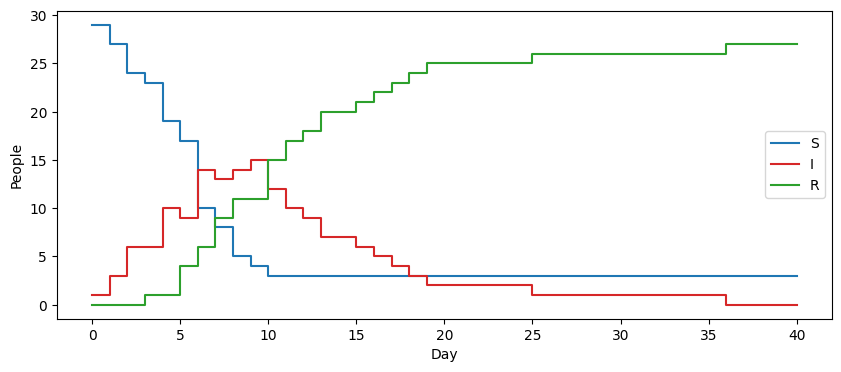

Population conserved? True


In [29]:
G = nx.erdos_renyi_graph(30, 0.12)
S, I, R, history = simulate(G, days=40)

plt.figure(figsize=(10, 4))
plt.step(range(len(S)), S, where="post", label="S", color="tab:blue")
plt.step(range(len(I)), I, where="post", label="I", color="tab:red")
plt.step(range(len(R)), R, where="post", label="R", color="tab:green")
plt.xlabel("Day"); plt.ylabel("People"); plt.legend(); plt.show()
print("Population conserved?", np.all(S + I + R == G.number_of_nodes()))

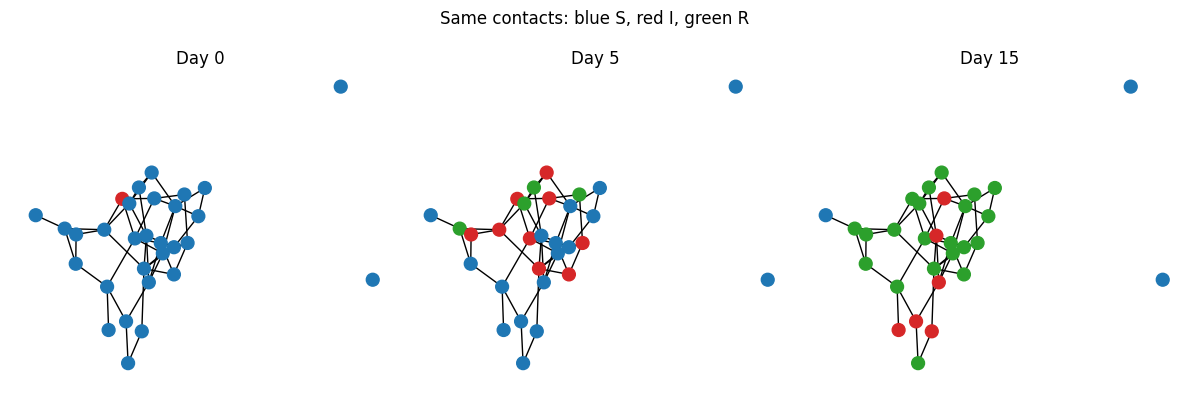

In [30]:
positions = nx.spring_layout(G, seed=4)
colours = {"S": "tab:blue", "I": "tab:red", "R": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, day in zip(axes, [0, 5, 15]):
    node_colours = []
    for person in G.nodes():
        node_colours.append(colours[history[day][person]])
    nx.draw(G, positions, ax=ax, node_color=node_colours, node_size=85)
    ax.set_title(f"Day {day}")
plt.suptitle("Same contacts: blue S, red I, green R")
plt.tight_layout(); plt.show()

### To Do

**1. Implement other epidemic models**

Try to implement other epidemic models (SI, SIS, SIRD, etc.) on the network, starting from our SIR implementation. 

**2. Simulate epidemic spreading using a library**

Use an existing Python library to reproduce the SIR dynamics we implemented from scratch. Compare the results!

**Hint:** Try [NDlib](https://github.com/GiulioRossetti/ndlib), a Python library for simulating diffusion processes on networks.

```python
import ndlib.models.epidemics as ep
import ndlib.models.ModelConfig as mc

model = ep.SIRModel(G)

config = mc.Configuration()
config.add_model_parameter("beta", 0.3)
config.add_model_parameter("gamma", 0.1)
config.add_model_initial_configuration("Infected", [0])

model.set_initial_status(config)
results = model.iteration_bunch(20)
```

**3. Experiment with different network structures**

Replace the simple path graph with a **Barabási–Albert network** using `nx.barabasi_albert_graph(n, m)`.

Run the SIR simulation again. How does the network topology affect the spread of infection? Compare the results with your original network.

In [16]:
import networkx as nx
import ndlib.models.ModelConfig as mc
import ndlib.models.epidemics as ep

# Network topology
g = nx.erdos_renyi_graph(1000, 0.1)

# Model selection
model = ep.SIRModel(g)

# Model Configuration
cfg = mc.Configuration()
cfg.add_model_parameter('beta', 0.01)
cfg.add_model_parameter('gamma', 0.005)
cfg.add_model_parameter("fraction_infected", 0.05)
model.set_initial_status(cfg)

# Simulation execution
iterations = model.iteration_bunch(200)

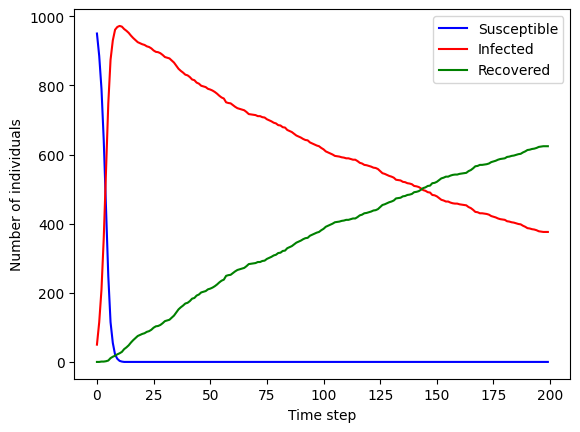

In [17]:
S = [it["node_count"][0] for it in iterations]
I = [it["node_count"][1] for it in iterations]
R = [it["node_count"][2] for it in iterations]

plt.plot(S, label="Susceptible", color="blue")
plt.plot(I, label="Infected", color="red")
plt.plot(R, label="Recovered", color="green")

plt.xlabel("Time step")
plt.ylabel("Number of individuals")
plt.legend()
plt.show()